In [1]:
%pip install alpaca-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [alpaca-py]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from dotenv import load_dotenv
from alpaca.data.historical import StockHistoricalDataClient

load_dotenv()

API_KEY = os.getenv("API_KEY")
SECRET_KEY = os.getenv("SECRET_KEY")

client = StockHistoricalDataClient(API_KEY, SECRET_KEY)

In [4]:
from alpaca.data.requests import StockLatestTradeRequest
from alpaca.data.enums import DataFeed

request = StockLatestTradeRequest(
    symbol_or_symbols="AAPL",
    feed=DataFeed.IEX
)

trade = client.get_stock_latest_trade(request)["AAPL"]

print("Price:", trade.price)
print("Timestamp:", trade.timestamp)

Price: 343.39
Timestamp: 2026-10-16 19:59:58.574873+00:00


In [7]:
from alpaca.data.requests import StockBarsRequest
from alpaca.data.timeframe import TimeFrame
from alpaca.data.enums import DataFeed
from datetime import datetime, timedelta, timezone

ticker = "AAPL"

end = datetime.now(timezone.utc)
start = end - timedelta(days=30)

request = StockBarsRequest(
    symbol_or_symbols=ticker,
    timeframe=TimeFrame.Hour,
    start=start,
    end=end,
    feed=DataFeed.IEX
)

bars = client.get_stock_bars(request)

df = bars.df.reset_index()
display(df.head())

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,AAPL,2026-09-17 12:00:00+00:00,334.53,334.550,334.100,334.140,888.0,23.0,334.290059
1,AAPL,2026-09-17 13:00:00+00:00,334.15,335.390,330.230,330.835,141162.0,3174.0,331.755899
2,AAPL,2026-09-17 14:00:00+00:00,330.81,333.845,330.750,332.725,118535.0,2959.0,332.807926
3,AAPL,2026-09-17 15:00:00+00:00,332.80,334.930,332.035,334.860,96039.0,2485.0,333.337879
4,AAPL,2026-09-17 16:00:00+00:00,334.91,336.400,334.860,336.110,148561.0,3428.0,335.704592


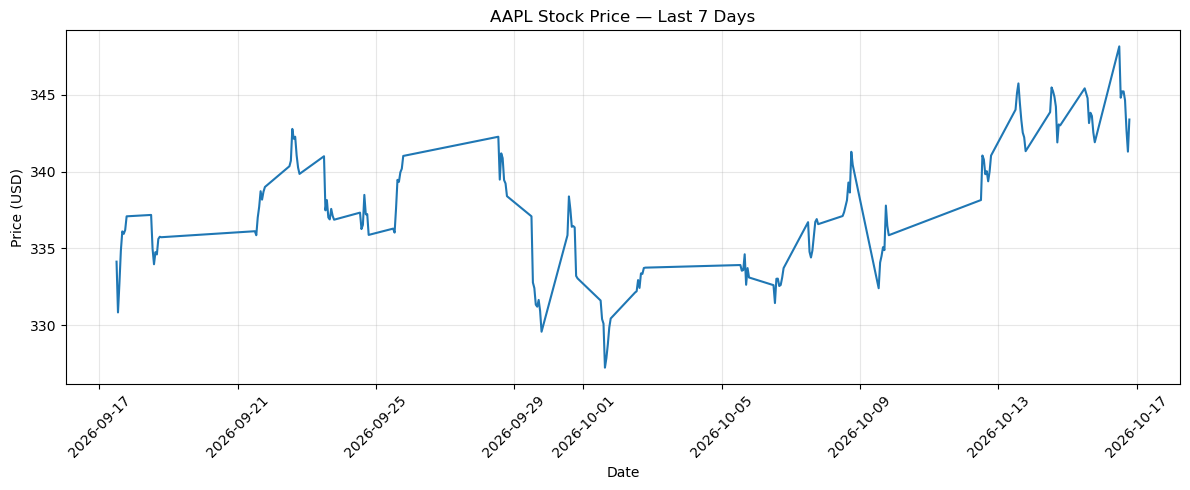

In [8]:
import matplotlib.pyplot as plt

df = df.sort_values("timestamp")

plt.figure(figsize=(12, 5))
plt.plot(df["timestamp"], df["close"])

plt.title(f"{ticker} Stock Price — Last 30 Days")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()